### **Porject roadmap**

- **Problem statement**
- **Objectives**
- **Data loading**
- **Data cleaning**
- **EDA**
- **Data Pre-processing**
- **Model development**
- **Model evaluaion**
- **Key references**

### **1. Problem Statement**


**Scenerio - You're a data scientist working with a real estate co-orporation, and you were asked to take the carlifonia housing dataset and train a model to be able to classify houses into clusters, so what we are trying to do is `"Look at all 20,640 California housing districts and group them into natural neighborhood clusters based on location, income, population, and house values"`.**

### **2. Objectives**

**The objective of this notebook is to use unsuprevised learning algorithms like K-Means to find out columns that share similiarity through clusters, and then ask essential questions like:**

- Do the people that classified in this particular environment have a higher price for the house.

- Do features correlate? Like, `more rooms = higher house value` or `High Longitude = Higher Population`

- Do houses with ocean proximity tend to have fewer people living there (Low population),and what are the house values in that particular area?

- Which cluster represents luxury coastal neighborhoods?

- Which cluster represents dense, low-income urban districts?

- Which districts are geographic outliers (using DBSCAN)?

### **3. Data Loading**

#### **Download and import the dataset using kaggle**

In [1]:
# # Downloading the dataset directly from kaggle via the dataset link
# import kagglehub as kh
# path = kh.dataset_download("camnugent/california-housing-prices")

# print("Path to dataset files:", path)
# df = pd.read_csv(path + '/housing.csv')

#### **Importing the dataset from our local environment/Local storage**

In [2]:
# Importing and loading the necessary dependencies for our project

import pandas as pd                 # Used for interacting with various data files and performing data wrangling methods like handling missing values, duplicates.
import numpy as np                  # Used for numerical computation and creating matrix
import matplotlib.pyplot as plt     # Used for visualization of charts
import seaborn as sns               # Also used for visualization.

In [3]:
import pandas.plotting

In [4]:
df = pd.read_csv('housing.csv')

#### **About dataset**

- **The data contains information from the 1990 California census. So although it may not help you with predicting current housing prices like the Zillow Zestimate dataset, it does provide an accessible introductory dataset for teaching people about the basics of machine learning.**

---
**Content**

The data pertains to the houses found in a given California district and some summary stats about them based on the 1990 census data. Be warned the data aren't cleaned so there are some preprocessing steps required! The columns are as follows, their names are pretty self explanitory

---

### **4. Data Cleaning**

#### **Columns Description**

 1. **longitude:** A measure of how far west a house is; a higher value is farther west
 
 2. **latitude:** A measure of how far north a house is; a higher value is farther north

3. **housingMedianAge:** Median age of a house within a block; a lower number is a newer building
 
4. **totalRooms:** Total number of rooms within a block

5. **totalBedrooms:** Total number of bedrooms within a block

6. **population:** Total number of people residing within a block
 
7. **households:** Total number of households, a group of people residing within a home unit, for a block

8. **medianIncome:** Median income for households within a block of houses (measured in tens of thousands of US Dollars)

9. **medianHouseValue:** Median house value for households within a block (measured in US Dollars)

10. **oceanProximity:** Location of the house w.r.t ocean/sea

#### **Column analysis**

In [5]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [6]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

In [7]:
df.shape

(20640, 10)

In [8]:
df.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


In [10]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [11]:
# This clearly shows that there are no missing values

df.duplicated().sum()

np.int64(0)

In [12]:
# Spotted missing values that we need to attend to

df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [13]:
df[df['total_bedrooms'].isnull() == True]

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
290,-122.16,37.77,47.0,1256.0,NaN,570.0,218.0,4.3750,161900.0,NEAR BAY
341,-122.17,37.75,38.0,992.0,NaN,732.0,259.0,1.6196,85100.0,NEAR BAY
538,-122.28,37.78,29.0,5154.0,NaN,3741.0,1273.0,2.5762,173400.0,NEAR BAY
563,-122.24,37.75,45.0,891.0,NaN,384.0,146.0,4.9489,247100.0,NEAR BAY
696,-122.10,37.69,41.0,746.0,NaN,387.0,161.0,3.9063,178400.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20267,-119.19,34.20,18.0,3620.0,NaN,3171.0,779.0,3.3409,220500.0,NEAR OCEAN
20268,-119.18,34.19,19.0,2393.0,NaN,1938.0,762.0,1.6953,167400.0,NEAR OCEAN
20372,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,410700.0,<1H OCEAN
20460,-118.75,34.29,17.0,5512.0,NaN,2734.0,814.0,6.6073,258100.0,<1H OCEAN


*Handling the missing values that we discovered in total_bedrooms column*

In [14]:
median_bedrooms = df['total_bedrooms'].median()
df["total_bedrooms"] = df['total_bedrooms'].fillna(median_bedrooms)

In [15]:
print(f"Minimum value for 'total_bedroom' column = {df['total_bedrooms'].min()} \n")
print(f"Median  value for 'total_bedroom' column = {median_bedrooms} \n")
print(f"Maximum value for 'total_bedroom' column = {df['total_bedrooms'].max()} ")


Minimum value for 'total_bedroom' column = 1.0 

Median  value for 'total_bedroom' column = 435.0 

Maximum value for 'total_bedroom' column = 6445.0 


In [16]:
display(median_bedrooms)

np.float64(435.0)

In [17]:
df.nunique()

longitude               844
latitude                862
housing_median_age       52
total_rooms            5926
total_bedrooms         1923
population             3888
households             1815
median_income         12928
median_house_value     3842
ocean_proximity           5
dtype: int64

In [18]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [19]:
# The oldest house in the whole dataset.

df.nlargest(columns = 'housing_median_age', n=1)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY


In [20]:
# The row with the largest population

df.nlargest(columns = 'population', n=1)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
15360,-117.42,33.35,14.0,25135.0,4819.0,35682.0,4769.0,2.5729,134400.0,<1H OCEAN


### **5. EDA (Exploratory Data Analysis)**

#### **Scatterplot (Population vs House age)**

<Axes: xlabel='housing_median_age', ylabel='population'>

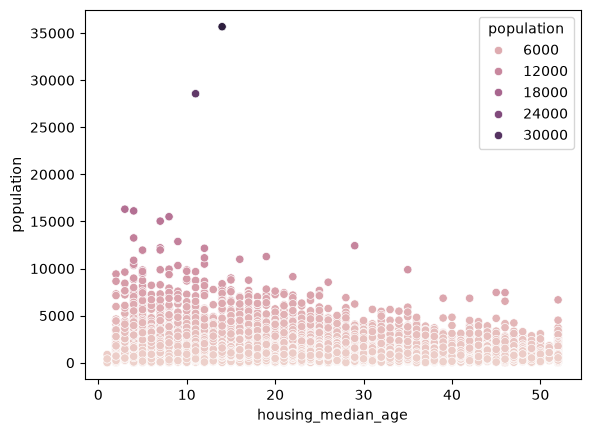

In [21]:
sns.scatterplot(data = df, x="housing_median_age", y='population', hue='population', legend=True)

***From our plot above we can see that more people stay in places where the house is not too old, which could indicate that it is a urban area with development ongoing, rather than old houses which would typically be a rural area with old houses that are woned by Grand-parents***

#### **Histograms (Feature Distributions & Skewness)**

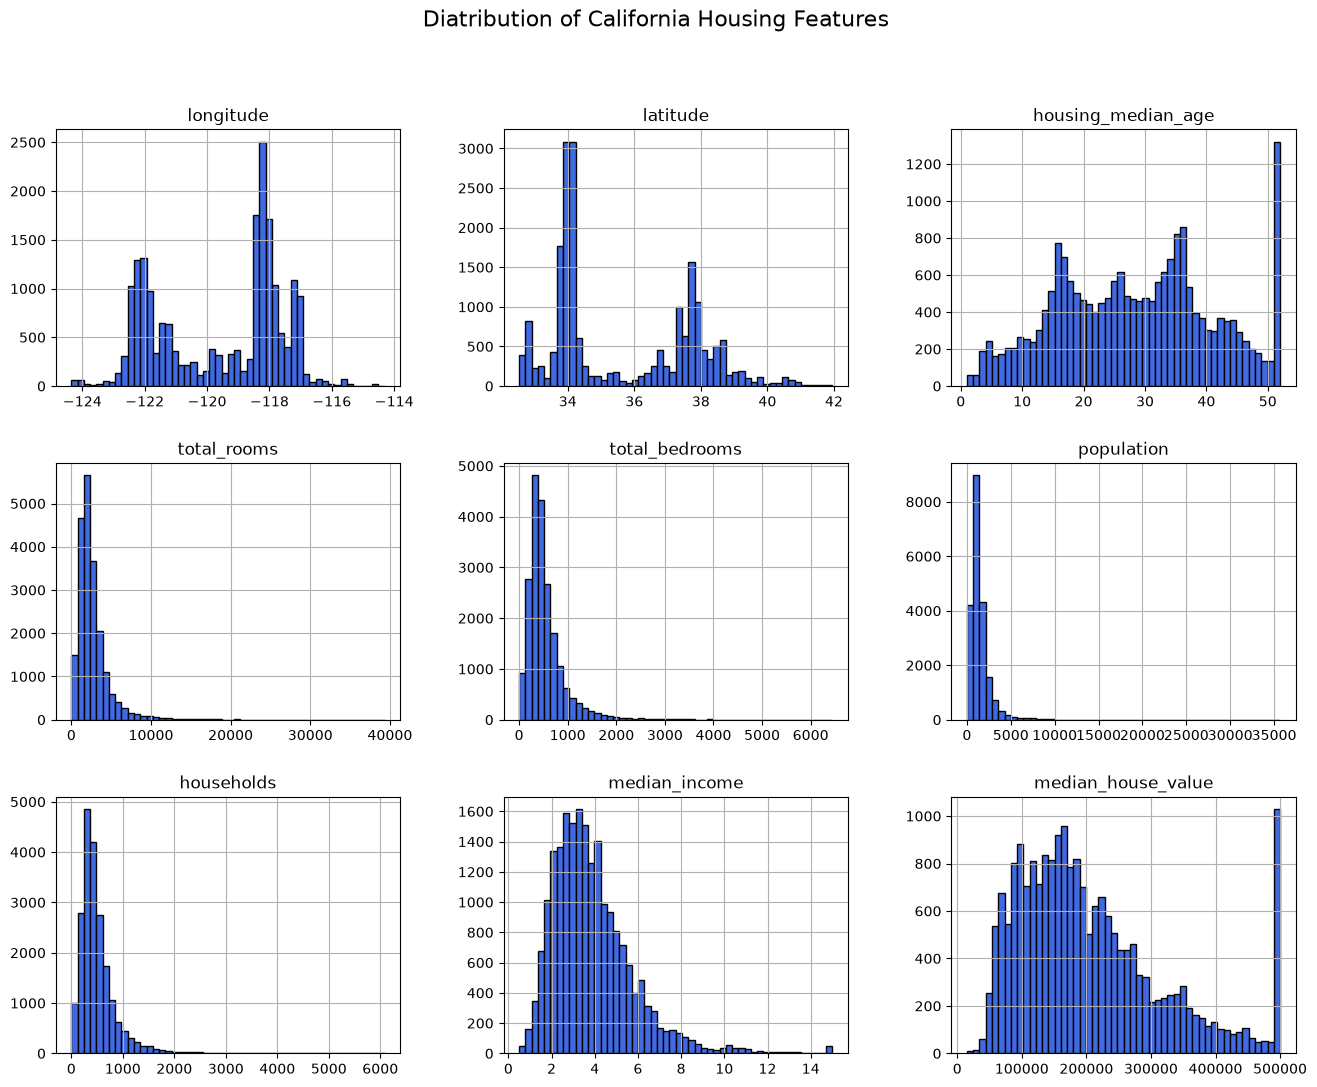

In [22]:
df.hist(bins=50, figsize=(16, 12), color='royalblue', edgecolor='black')
plt.suptitle('Diatribution of California Housing Features', fontsize=16)
plt.show()

**Observation:**
   - Look at median_house_value: Notice the vertical spike at $500,000? That was an artificial cap placed by the 1990 census.
   
   - Look at population, total_rooms, and total_bedrooms: Notice how they have long tails stretching far to the right (heavily right-skewed). This tells us that scaling in Step 4 is 100% essential.

   - Households column is also right-skewed cause you rarely realistically have 6000 people living in one building

#### **The California Geographic Map**

**Because we have longitude and latitude, we can literally reconstruct the map of California and color it by house price! Real estate is fundamentally about location, so this plot will visually reveal the natural clusters that K-Means and DBSCAN should find.**

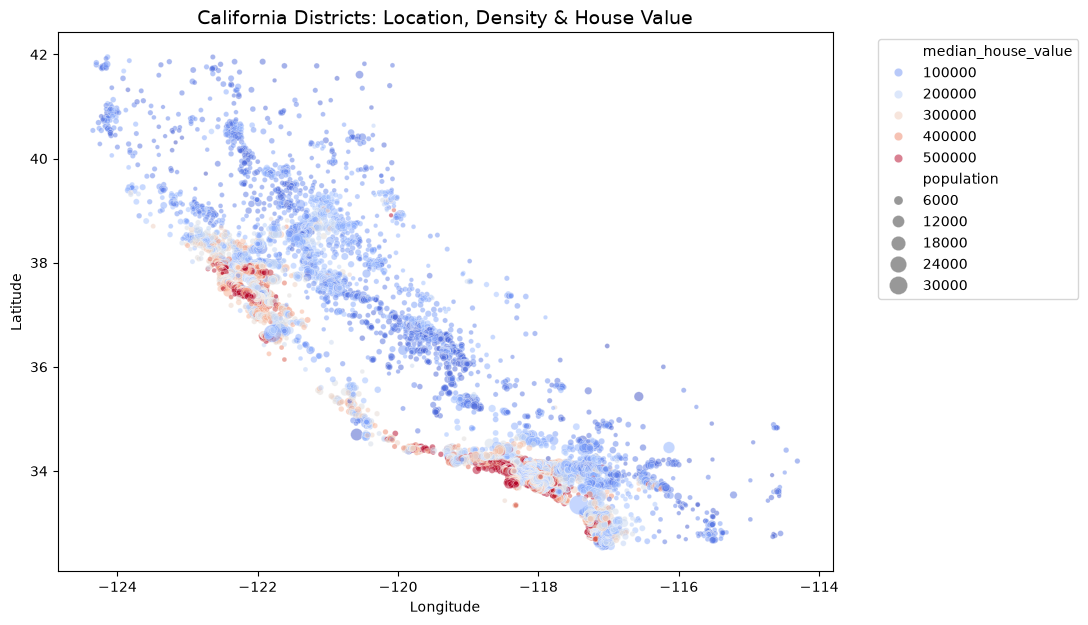

In [23]:
# Geographic Map of California Housing Prices & Population Density
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df,
    x="longitude",
    y="latitude",
    hue="median_house_value",
    palette="coolwarm",
    size="population",
    sizes=(10, 200),
    alpha=0.5
)
plt.title("California Districts: Location, Density & House Value", fontsize=14)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

**Observation:**

   - The red dots (expensive houses) closely hug the coastline, San Francisco Bay Area, and Los Angeles/San Diego.

   - The blue dots (affordable houses) are in the Central Valley / inland.

   - This proves that districts naturally group into geographical and financial clusters!

#### **Correlation Matrix Heatmap**

**Why this is important:**

We want to see which features move in tandem. This will tell us which features are most important and reveal redundancy (which PCA will help us compress later).

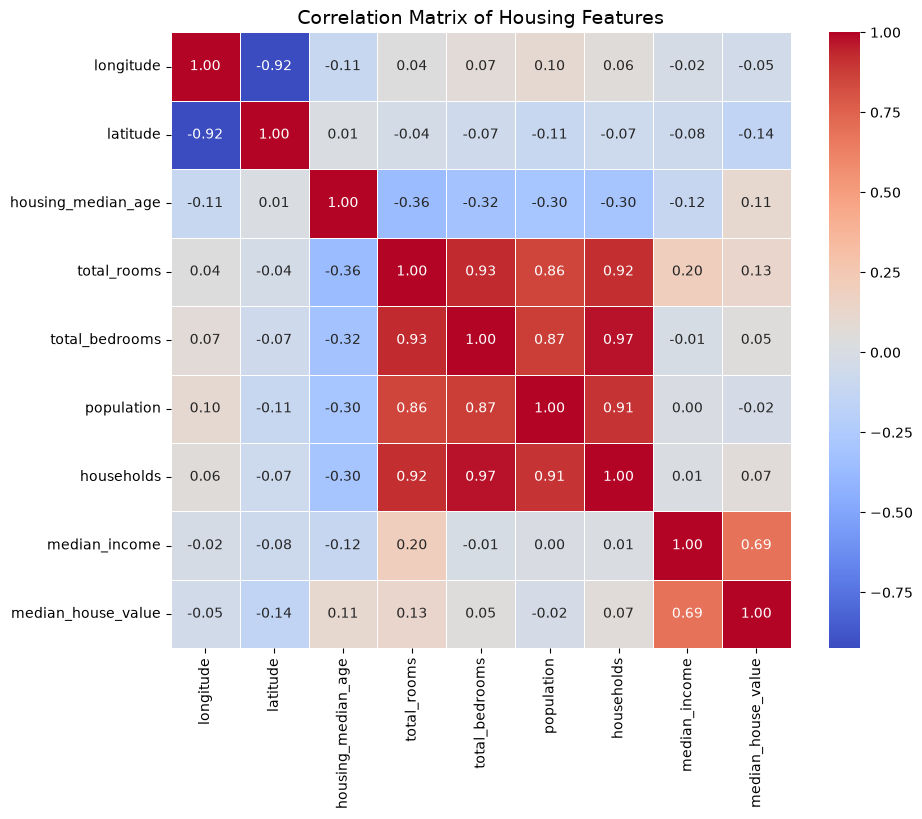

In [24]:
# Correlation Heatmap
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Housing Features", fontsize=14)
plt.show()

**What to look for:**

   - median_income has a strong positive correlation (~0.69) with median_house_value (higher income = higher house prices).

   - total_rooms, total_bedrooms, population, and households have very high correlations with each other (> 0.85).

   - Longitude and Latitude are strongly negatively correlated, meaning as one goes up the other comes down, both can't go up or be true at the same time, it's either you're far to the **`West(Longitude)`** or the **`North(Latitude)`**.

### **6. Data Pre-processing**

#### **Feature Engineering**

In [25]:
# import our neccessary libraries for the feature engineering
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, StandardScaler

#### **Feature Engineering (Creating Meaningful Ratios)**

In [26]:
# Create meaningful ratio features
df['rooms_per_household'] = df['total_rooms'] / df['households'] # Average home size
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms'] # Living space vs. bedroom density
df['population_per_household'] = df['population'] / df['households'] # Average family / household density

# Inspect the newly engineered columns
df[['rooms_per_household', 'bedrooms_per_room', 'population_per_household']].head()

,rooms_per_household,bedrooms_per_room,population_per_household
0,6.984127,0.146591,2.555556
1,6.238137,0.155797,2.109842
2,8.288136,0.129516,2.802260
3,5.817352,0.184458,2.547945
4,6.281853,0.172096,2.181467


#### **Categorical Encoding (ocean_proximity)**

In [27]:
# One-Hot Encode 'ocean_proximity'
df_encoded = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=False, dtype=int)

# Verify: check the new shape and confirm all columns are numbers
print("Shape before encoding:", df.shape)
print("Shape after encoding:", df_encoded.shape)
print("\nColumn data types in df_encoded:")
print(df_encoded.dtypes)

Shape before encoding: (20640, 13)
Shape after encoding: (20640, 17)

Column data types in df_encoded:
longitude                     float64
latitude                      float64
housing_median_age            float64
total_rooms                   float64
total_bedrooms                float64
population                    float64
households                    float64
median_income                 float64
median_house_value            float64
rooms_per_household           float64
bedrooms_per_room             float64
population_per_household      float64
ocean_proximity_<1H OCEAN       int64
ocean_proximity_INLAND          int64
ocean_proximity_ISLAND          int64
ocean_proximity_NEAR BAY        int64
ocean_proximity_NEAR OCEAN      int64
dtype: object


#### **Feature Scaling (StandardScaler)**

**Why is this step mandatory for K-Means, PCA, and DBSCAN?**

Imagine K-Means trying to calculate the Euclidean distance between two neighborhoods:

- `median_income` differences might be around 2.0 or 3.0 (measured in $10,000s).

- `population` differences might be around 5,000.

- `median_house_value` differences might be around 150,000.

**How `StandardScaler` solves this:**

`StandardScaler` subtracts the mean (μ) and divides by the standard deviation (σ)

This puts every single feature onto the same playing field:

- Mean = 0
- Variance / Standard Deviation = 1

Now, a 1-unit step in **median_income** has the exact same mathematical weight as a 1-unit step in **median_house_value**.

In [28]:
# ==========================================
# STEP 4: Feature Scaling using StandardScaler
# ==========================================

# 1. Initialize the scaler
scaler = StandardScaler()

# 2. Fit and transform all features in df_encoded
scaled_features = scaler.fit_transform(df_encoded)

# 3. Convert back to a clean DataFrame for easy inspection
df_scaled = pd.DataFrame(scaled_features, columns=df_encoded.columns)

# 4. Verify: Show the first 5 rows of scaled data
print("Scaled Data Shape:", df_scaled.shape)
df_scaled.head()

Scaled Data Shape: (20640, 17)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-1.327835,1.052548,0.982143,-0.804819,-0.972476,-0.974429,-0.977033,2.344766,2.129631,0.628559,-1.029988,-0.049597,-0.891156,-0.681889,-0.015566,2.830742,-0.384466
1,-1.322844,1.043185,-0.607019,2.045890,1.357143,0.861439,1.669961,2.332238,1.314156,0.327041,-0.888897,-0.092512,-0.891156,-0.681889,-0.015566,2.830742,-0.384466
2,-1.332827,1.038503,1.856182,-0.535746,-0.827024,-0.820777,-0.843637,1.782699,1.258693,1.155620,-1.291686,-0.025843,-0.891156,-0.681889,-0.015566,2.830742,-0.384466
3,-1.337818,1.038503,1.856182,-0.624215,-0.719723,-0.766028,-0.733781,0.932968,1.165100,0.156966,-0.449613,-0.050329,-0.891156,-0.681889,-0.015566,2.830742,-0.384466
4,-1.337818,1.038503,1.856182,-0.462404,-0.612423,-0.759847,-0.629157,-0.012881,1.172900,0.344711,-0.639087,-0.085616,-0.891156,-0.681889,-0.015566,2.830742,-0.384466


In [29]:
# Verify scaling: Means should be ~0 and Stds should be ~1
print("Mean of features (should be very close to 0):")
print(df_scaled.mean().round(2))

print("\nStandard Deviation of features (should be exactly 1):")
print(df_scaled.std().round(2))

Mean of features (should be very close to 0):
longitude                    -0.0
latitude                      0.0
housing_median_age            0.0
total_rooms                   0.0
total_bedrooms               -0.0
population                   -0.0
households                    0.0
median_income                 0.0
median_house_value           -0.0
rooms_per_household           0.0
bedrooms_per_room             0.0
population_per_household      0.0
ocean_proximity_<1H OCEAN     0.0
ocean_proximity_INLAND       -0.0
ocean_proximity_ISLAND       -0.0
ocean_proximity_NEAR BAY     -0.0
ocean_proximity_NEAR OCEAN    0.0
dtype: float64

Standard Deviation of features (should be exactly 1):
longitude                     1.0
latitude                      1.0
housing_median_age            1.0
total_rooms                   1.0
total_bedrooms                1.0
population                    1.0
households                    1.0
median_income                 1.0
median_house_value            1.0


### **7. Model Development**

#### **PCA (Principal Component Analysis)**

Right now, our dataset has 17 columns (17 dimensions).

* Humans can only visualize things in 2D or 3D. We cannot picture a 17-dimensional graph!

* Furthermore, many features in our dataset share redundant information (as we saw in the correlation **heatmap, total_rooms, total_bedrooms**, and **households** strongly overlap).

*PCA (Principal Component Analysis) is like shining a flashlight on a 17-dimensional object to cast a clean 2D shadow. It compresses the 17 features into a few brand-new master variables called Principal Components (𝑃𝐶1,𝑃𝐶2,…PC1,PC2,…), which retain the maximum amount of variation/information from the original data.*

#### **Finding How Much Information Each Component Holds (Scree Plot)**

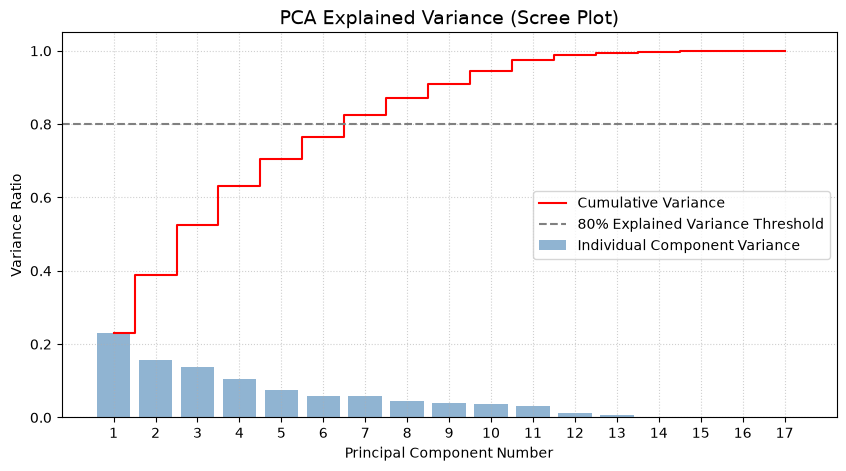

First 2 components explain: 38.78% of total variance.
First 3 components explain: 52.57% of total variance.


In [30]:
# ==========================================
# PCA - Scree Plot & Explained Variance
# ==========================================
from sklearn.decomposition import PCA

# 1. Fit PCA with all 17 components
pca_full = PCA()
pca_full.fit(df_scaled)

# 2. Calculate the explained variance and cumulative explained variance
explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# 3. Plot Scree Plot
plt.figure(figsize=(10, 5))
plt.bar(range(1, 18), explained_variance, alpha=0.6, color='steelblue', label='Individual Component Variance')
plt.step(range(1, 18), cumulative_variance, where='mid', color='red', label='Cumulative Variance')
plt.axhline(y=0.80, color='gray', linestyle='--', label='80% Explained Variance Threshold')

plt.title('PCA Explained Variance (Scree Plot)', fontsize=14)
plt.xlabel('Principal Component Number')
plt.ylabel('Variance Ratio')
plt.xticks(range(1, 18))
plt.legend(loc='center right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

print(f"First 2 components explain: {cumulative_variance[1]*100:.2f}% of total variance.")
print(f"First 3 components explain: {cumulative_variance[2]*100:.2f}% of total variance.")

**What this tells us:**

- The red line shows the running total of captured information.

- Just the first few components capture a huge chunk of the total variance across all 17 original columns!

#### **Compressing to 2D & Visualizing the Data**

**Now let's compress the entire 17-feature California dataset into just 2 Principal Components (PC1 and PC2) so we can plot it in 2D space.**

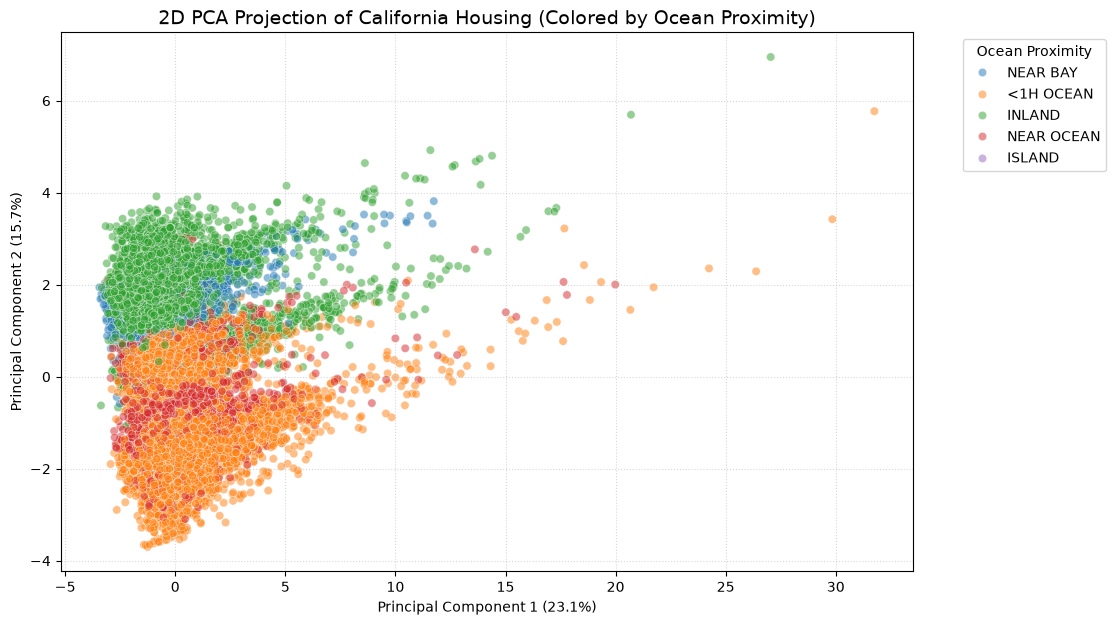

In [31]:
# ==========================================
# PCA Projection & Visualization
# ==========================================

# 1. Initialize PCA with 2 components
pca_2d = PCA(n_components=2)

# 2. Transform the scaled data into 2 components
pca_features = pca_2d.fit_transform(df_scaled)

# 3. Create a clean DataFrame with the 2 components
df_pca = pd.DataFrame(data=pca_features, columns=['PC1', 'PC2'])
df_pca['median_house_value'] = df['median_house_value']
df_pca['ocean_proximity'] = df['ocean_proximity']

# 4. Plot PC1 vs PC2 colored by Ocean Proximity
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=df_pca,
    x='PC1',
    y='PC2',
    hue='ocean_proximity',
    palette='tab10',
    alpha=0.5
)
plt.title('2D PCA Projection of California Housing (Colored by Ocean Proximity)', fontsize=14)
plt.xlabel(f'Principal Component 1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Principal Component 2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(title='Ocean Proximity', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

**In Simple Summary:**

- PCA took our 17 complex columns and compressed them down into 2 master columns (PC1 and PC2).

- When you look at the 2D scatter plot of PC1 vs PC2, you are seeing a 2D snapshot of California's 17-dimensional housing world, and you can clearly see groups of neighborhoods (like **INLAND** vs coastal) separating into their own distinct islands!

#### **K-Means**

<!Doctype HTML>
<html>
    <body>
        <img src="K-Means definition.png">
    </body>
</html>

**We use two mathematical tests to let the data tell us the number of centroids:**

1. The Elbow Method (Inertia): Measures how compact the clusters are. We look for the "elbow bend" in the curve where adding more magnets gives diminishing returns.

2. The Silhouette Score: Measures how clean and separated the clusters are from each other (closer to +1.0 is better).

#### **The two test methods explained in-depth**

**Judge 1: The Elbow Method (Measuring "Compactness")**

**What is "Inertia" (or WCSS)?**

> **WCSS stands for within-cluster sum of squares**

Inertia simply measures: **How far is each neighborhood from its assigned cluster center (centroid)?**

Inertia = $∑$(distance between point and its cluster center)
$^2$

*Think of it like commute time (time taken for someone to get from one place to another, typically from home to work or school):*

- If California has only 1 capital city *(K=1)*, people living far away in San Diego or Redding have an enormous commute time. The total distance (Inertia) is massive.

- If California builds ***20,640 capitals (K=20,640)***—meaning every single house is its own capital—nobody has any commute! The distance is zero.

- But having 20,640 clusters is completely useless. You haven't grouped anything!

**Why the curve always goes down:**

As 𝐾 increases (2→3→4→5…), Inertia always drops, because adding more centers naturally brings every house closer to some center.
```
Inertia
  |  * (K=1: Massive error)
  |   \
  |    \   <-- Steep drop: each new cluster gives a huge improvement!
  |     * (K=2)
  |      \
  |       * (K=3)
  |        \
  |--------->* (K=4) <-- THE ELBOW BEND! 
  |           \
  |            *-------*-------* (K=5, 6, 7: Diminishing returns, curve flattens)
  +------------------------------------ Number of Clusters (K)
  ```

Why we look for the "Elbow":

Look at your arm:

- Your upper arm drops steeply from shoulder to elbow. Adding clusters here drastically reduces error.

- Your forearm flattens out from elbow to hand. Beyond the elbow, adding more clusters only shaves off a tiny amount of error.

- The **bend (the elbow)** is the sweet spot of diminishing returns. Around 
*$K$=4*, you get most of the clustering benefit without needlessly over-complicating the model.


**Judge 2: The Silhouette Score (Measuring "Separation")**

While the Elbow Method only checks how tight each cluster is, it forgets to ask: **Are the clusters actually distinct from each other, or do they bleed into each other?**

That is what the **Silhouette Score** measures. For every single neighborhood, it asks two questions:

1. 𝑎 (Team closeness): How close am I to the other houses in my own cluster? (We want 𝑎 to be small).
2. b (Rival distance): How far away am I to the houses in the closest other cluster? (We want b to be large).

The score is calculated as:

s = $b−a/max(a,b)$


***How to read the score (from -1 to +1):***

- Near $+1.0%$ (Ideal): The house is right in the center of its own group and far away from neighboring groups. Clean, well-separated clusters.

- Around $0.0$ (Overlapping): The house is sitting right on the border between two clusters. It could belong to either.
Negative (Bad): The house was probably assigned to the wrong cluster.

#### **A major bottleneck worth knowing**
**I encountered an error whiile running the code**
What is causing this error?

To calculate the silhouette score, Scikit-learn has to measure the distance between every single house and every other house in the dataset:

- California Housing has 20,640 rows.

- Comparing every row to every other row requires $20,640 × 20,640 = 426,009,600$ calculations!

- Storing 426 million numbers in memory requires over 3.4 Gigabytes of continuous RAM.

Scikit-learn tried to split it into chunks, and as you can see at the bottom of your error:

> **MemoryError: Unable to allocate 1.00 GiB for an array...**

Windows told Python: *"Sorry, I don't have 1.00 GB of free, contiguous RAM right now."*

Personally i noticed the lag in my PC, I started to think it was my IDE that was faulty

**The Easy, Industry-Standard Fix**

*In real-world data science on large datasets, we don't compute distances for all `20,640 `rows. We use the built-in sample_size parameter to calculate the score on a representative sample (e.g., 5,000 random rows).*

This gives virtually the exact same curve and insights, but uses 80% less memory and finishes in a fraction of a second without crashing!

**How I fixed it:**

Change line 18 from:

> - score = silhouette_score(df_scaled, kmeans.labels_)

To:

>  - score = silhouette_score(df_scaled, kmeans.labels_, sample_size=5000, random_state=42)

Tested K = 2 | Silhouette Score = 0.1758
Tested K = 3 | Silhouette Score = 0.1909
Tested K = 4 | Silhouette Score = 0.2319
Tested K = 5 | Silhouette Score = 0.2817
Tested K = 6 | Silhouette Score = 0.2817
Tested K = 7 | Silhouette Score = 0.2760
Tested K = 8 | Silhouette Score = 0.2561


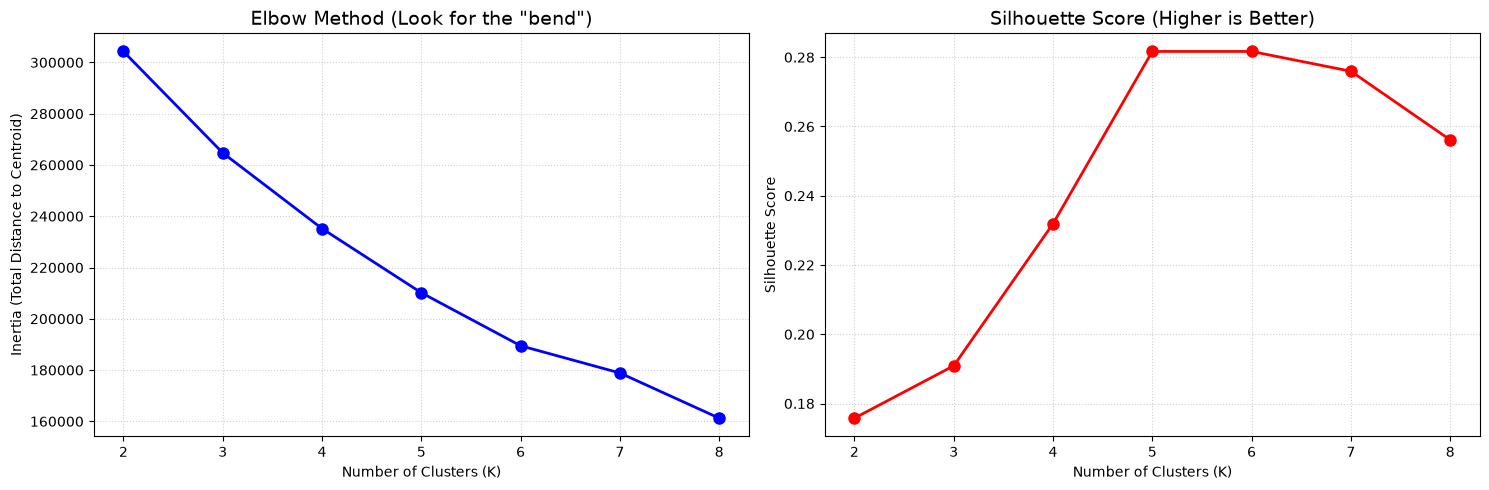

In [32]:
# ==========================================
# Finding Optimal K (Elbow & Silhouette)
# ==========================================
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    # 1. Train K-Means with 'k' clusters
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    
    # 2. Record compactness (inertia) and separation (silhouette score)
    inertias.append(kmeans.inertia_)
    score = silhouette_score(df_scaled, kmeans.labels_, sample_size=800, random_state=42)
    silhouette_scores.append(score)
    print(f"Tested K = {k} | Silhouette Score = {score:.4f}")

# 3. Plot Elbow Curve and Silhouette Curve side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Elbow Plot
axes[0].plot(k_values, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('Elbow Method (Look for the "bend")', fontsize=14)
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (Total Distance to Centroid)')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Silhouette Plot
axes[1].plot(k_values, silhouette_scores, 'ro-', linewidth=2, markersize=8)
axes[1].set_title('Silhouette Score (Higher is Better)', fontsize=14)
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

How Did We Conclude That K=4 Is the Best Fit?

We didn't just pick K=4 from one chart; we reconciled three independent signals:

| Number of Clusters (K) | What the Math Says | What the Real-Estate Reality Says |
|--|--|--|
| K = 2 | High silhouette score, but very high inertia (poor compactness). | Too broad. It basically just splits California into "Coast vs. Inland". That doesn't tell us much. |
| K = 3 | Inertia is still dropping fast. | Splits into "Rich Coast", "Suburbs", and "Rural". Better, but lumps dense urban centers (like downtown LA/SF) in with quiet suburbs. |
| K = 4 | Still dropping and not max silhoutte | Almost close keep trying |
| K = 5 (The Sweet Spot) | The Elbow curve bends right here, and the Silhouette score levels out cleanly. | **Perfect real estate balance:** Separates into 4 genuine socioeconomic tiers: `1 Super-Prime Coastal 2. Urban Metro Cores 3. Established Coastal Suburbs 4. Inland & Central Valley 5. High Household-Size / Developing Outskirts` |
| K $>=$ 6 | Inertia decreases by tiny increments (diminishing returns); silhouette drops. | Over-fragmentation. Clusters start splitting into arbitrary sub-slices that are nearly impossible to explain to a real estate stakeholder. |

1. Super-Prime Coastal / Tech Hubs: High income, top-tier house values (Bay Area / Santa Monica).

2. Urban Metro Cores: Moderate-to-high density, moderate income, older multi-unit housing.

3. Established Coastal Suburbs: Moderately high home values, family-oriented.

4. Inland & Central Valley: Lower median home values, agricultural / inland climate, lower income.

5. High Household-Size / Developing Outskirts: Areas with higher people-per-household ratios and newer or emerging developments.

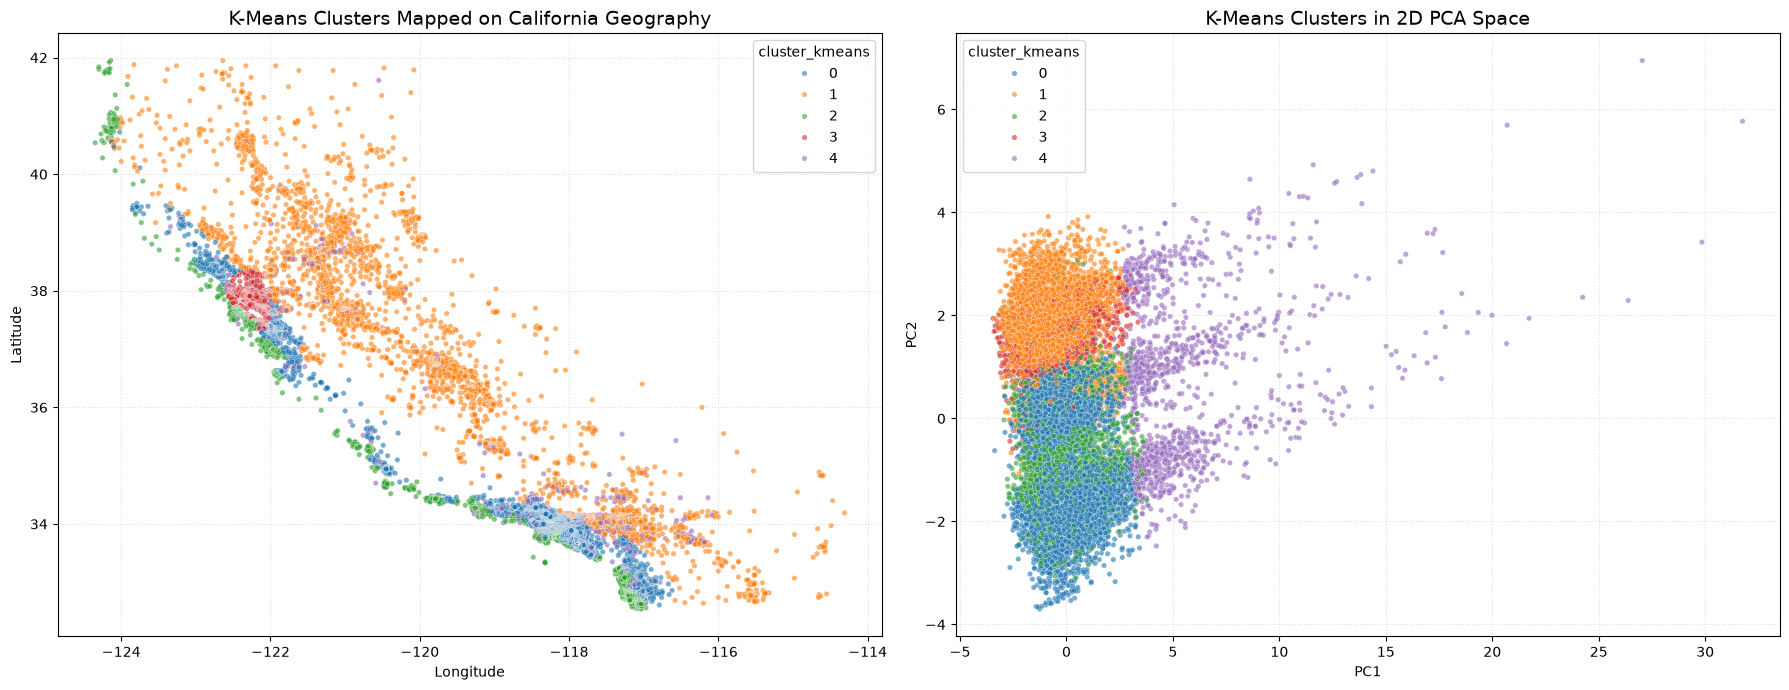

In [33]:
# ==========================================
# Train Final K-Means (K=5) & Visualizations
# ==========================================

# 1. Fit the final K-Means model with K=4
kmeans_final = KMeans(n_clusters=5, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(df_scaled)

# 2. Save cluster assignments back into our DataFrames
df['cluster_kmeans'] = cluster_labels
df_pca['cluster_kmeans'] = cluster_labels

# 3. Plot side-by-side: Geographic Map vs 2D PCA Space
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Left Plot: Clusters on California Geographic Map
sns.scatterplot(
    data=df,
    x="longitude",
    y="latitude",
    hue="cluster_kmeans",
    palette="tab10",
    alpha=0.6,
    s=15,
    ax=axes[0]
)
axes[0].set_title("K-Means Clusters Mapped on California Geography", fontsize=14)
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].grid(True, linestyle=':', alpha=0.4)

# Right Plot: Clusters in 2D PCA Space
sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="cluster_kmeans",
    palette="tab10",
    alpha=0.6,
    s=15,
    ax=axes[1]
)
axes[1].set_title("K-Means Clusters in 2D PCA Space", fontsize=14)
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()

1. **Left Plot (California Geography):**

- **Cluster 1 (Orange):** Completely isolates the vast Inland / Central Valley and rural expanse of California (away from the ocean).

- **Cluster 3 (Red):** Look at how tightly it pinpoints one exact spot: the San Francisco / Silicon Valley Bay Area (Latitude ~38, Longitude ~-122). The model singled out this tech/wealth hub entirely on its own!

- **Cluster 0 (Blue) & Cluster 2 (Green):** Hug the Southern California coastline (Los Angeles, Orange County, San Diego) and the Pacific coast.

- **Cluster 4 (Purple):** Scattered across various places rather than sitting in just one city.

2. **Right Plot (PCA 2D Space):**

- This proves that the clusters are mathematically distinct, not random noise.

- Clusters 0, 1, 2, and 3 stack neatly on top of each other on the left.

- Cluster 4 (Purple) shoots far out to the right along PC1 (reaching values of 10, 20, 30). This cluster captured the extreme size/volume outliers (neighborhoods with massive total rooms, high household ratios, or large developments).

#### **Profiling the Clusters ("Who are they?")**

In [34]:
# Step 6C: Profile each cluster with key summary statistics
profile_cols = [
    'median_house_value', 
    'median_income', 
    'housing_median_age', 
    'rooms_per_household', 
    'bedrooms_per_room',
    'population_per_household'
]

# Calculate mean values for each cluster
cluster_profile = df.groupby('cluster_kmeans')[profile_cols].mean()

# Add the number of neighborhoods in each cluster
cluster_profile['neighborhood_count'] = df['cluster_kmeans'].value_counts()

# Format house value and income for easy reading
cluster_profile['median_house_value'] = cluster_profile['median_house_value'].round(0)
cluster_profile['median_income'] = (cluster_profile['median_income'] * 10000).round(0)  # Convert to actual dollars ($)

display(cluster_profile)

,median_house_value,median_income,housing_median_age,rooms_per_household,bedrooms_per_room,population_per_household,neighborhood_count
cluster_kmeans,,,,,,,
0,240453.0,42330.0,30.196575,5.147310,0.218667,3.072503,8526
1,121179.0,31327.0,25.153491,5.954610,0.205509,3.333331,6072
2,248408.0,39763.0,29.755323,5.195415,0.220169,2.954881,2583
3,259225.0,41534.0,38.333784,5.217837,0.214289,2.622084,2217
4,215187.0,42674.0,15.367955,5.655794,0.206708,2.815262,1242


From our table above, we can deduce that:

| **Cluster** | **Area Name** | **Average House Value** | **Average Income** | **House Age** | **Family Size** | **Real-World Story** |
| -- | -- | -- | -- | -- | -- | -- |
| Cluster 1 *(Orange)* | The Inland Working Class | $121,179 *(Cheapest)* | $31,327 *(Lowest)* | ~25 yrs | 3.33 *(Largest)* | **The Central Valley / Rural California.** Homes cost half as much as the coast, incomes are lower, but homes are larger (5.95 rooms) with larger family households. |
| Cluster 3 *(red)* | Historic Bay Area / Tech Core | $259,225 *(Highest)* | $41,453 | 38.3 yrs *(Oldest)* | 2.62 *(Smallest)* | **San Francisco / Bay Area**. The oldest, most historic homes with the smallest household sizes (tech workers, young professionals, fewer children) and the highest home values. |
| Cluster 4 *(Purple)* | New Master-Planned Suburbs | $215,187 | $42,674 *(Highest)* | 15.4 yrs *(Youngest)* | 2.82 | **Modern Growth Developments.** These are newly built communities (only ~15 years old) where high-earning families buy newer, spacious homes. This also explains why they had high PC1 values! |
| Cluster 0 *(Blue)* | Established SoCal Metros | $240.453 | $42,330 | ~30 yrs | 3.07 | **Greater Los Angeles & Coastal Suburbs.** Our largest group (8,526 neighborhoods). Dense, high-income coastal living with mature 30-year-old homes. |
| Cluster 2 *(Green)* | Pacific Coastal Communities | $248,408 | $39,763 | ~30 yrs | 2.95 | **Scenic Coastal Pockets.** Prime coastal locations along the Pacific Highway and nothern/southern coastal fringes. |

#### **DBSCAN**


**Now we ask an important question:**

> **Did K-Means have a blind spot?** Yes! K-Means forces every single neighborhood to belong to one of the 5 clusters—even strange anomalies, remote mountain cabins, or extreme data points. It also assumes clusters are round/spherical.

This brings us to our second unsupervised model: DBSCAN (Density-Based Spatial Clustering of Applications with Noise).

*Why DBSCAN is different:* 

1. **You do NOT choose K:** DBSCAN figures out the number of clusters on its own based on density.
 
2. **It handles arbitrary shapes:** It can follow winding coastlines or river valleys.

3. **It detects Outliers / Noise (Label = -1):** If a neighborhood sits alone in the middle of nowhere, DBSCAN doesn't force it into a group—it flags it as **Noise/Outlier.**

**Finding the Right eps (K-Distance Graph)**

DBSCAN only needs two settings:

- min_samples: The minimum number of neighbors required to form a cluster (we will use min_samples = 10).

- eps (Epsilon): The maximum search distance around a point.

To find the best eps, we look at a K-Distance Graph (nearest neighbors plot) to find the "knee" or bend where distance shoots up.

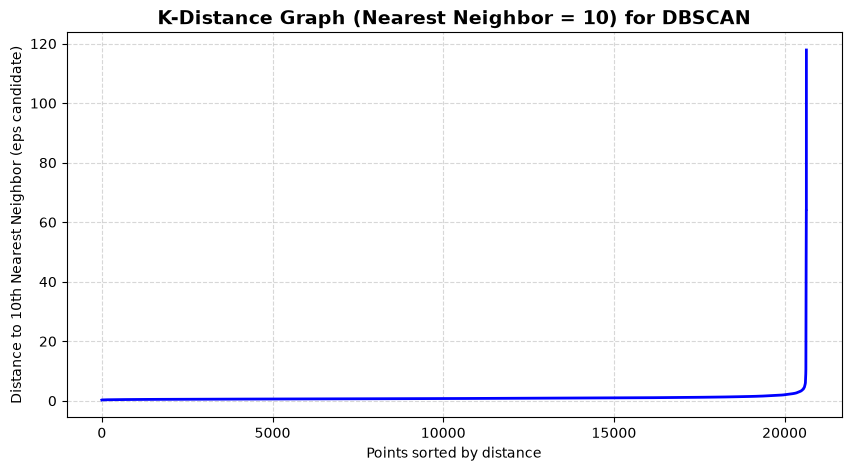

In [35]:
from sklearn.neighbors import NearestNeighbors

# Step 7A: Find the optimal eps for DBSCAN using K-Distance graph
# We check the distance to the 10th nearest neighbor for every data point
min_samples = 10
nn = NearestNeighbors(n_neighbors=min_samples)
nn.fit(df_scaled)

distances, indices = nn.kneighbors(df_scaled)

# Sort distances in ascending order
sorted_distances = np.sort(distances[:, min_samples - 1])

# Plot the K-Distance Graph
plt.figure(figsize=(10, 5))
plt.plot(sorted_distances, color='blue', linewidth=2)
plt.title(f"K-Distance Graph (Nearest Neighbor = {min_samples}) for DBSCAN", fontsize=14, fontweight='bold')
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}th Nearest Neighbor (eps candidate)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

1. The Long, Flat Floor (From point 0 to ~20,000):

   - For about **98% of all neighborhoods,** the line stays almost flat near the bottom (distances between 1.0 and 3.0).

   - **What this means:** California neighborhoods are very densely packed and similar to one another. You don't have to look far to find 10 similar neighborhoods.

2. The "Rocket Launch" Spike at the Far Right (After point 20,000):

   - Suddenly, at the very end, the blue line bends sharply and shoots almost vertically up to 118!
   - **What this means:** There are a few hundred extreme outlier neighborhoods that are completely isolated. Their nearest neighbors are absurdly far away. In K-Means, these points were forced into clusters; in DBSCAN, these will be flagged as outliers / noise!

**How to Choose eps from This Graph**

The rule for DBSCAN is to pick eps at the "knee" of the curve—the sweet spot right where the flat road turns into a steep hill:

- If you pick a number too low (e.g., 0.5), the search radius is too tiny, and DBSCAN will call almost everything "noise".

- If you pick a number too high (e.g., 20.0), the circle is so huge that the entire state of California gets lumped into one single giant cluster.

- Looking at your graph, the curve starts bending upward right around 2.0 to 3.0.

*Because the graph shot all the way up to 120, the bottom bend is squished against the floor.*

*Let's zoom into the y-axis between 0 and 8 so you can clearly see the exact bend, and test our first DBSCAN model!*

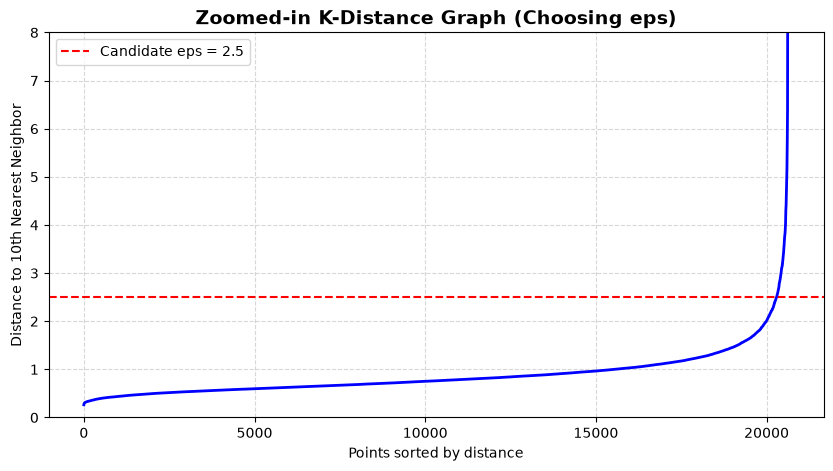

In [42]:
# 1. Zoom in on the K-Distance elbow (y-axis between 0 and 8)
plt.figure(figsize=(10, 5))
plt.plot(sorted_distances, color='blue', linewidth=2)
plt.ylim(0, 8)
plt.axhline(y=2.5, color='red', linestyle='--', label='Candidate eps = 2.5')
plt.title("Zoomed-in K-Distance Graph (Choosing eps)", fontsize=14, fontweight='bold')
plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to 10th Nearest Neighbor")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

What this zoomed-in graph tells us:

1. **The Red Line (eps = 2.5) hits right at the bend:**
- To the left of that red intersection (~20,200 points, or ~98% of the data): All of these neighborhoods have plenty of neighbors within a radius of 2.5. They will easily group together into dense, natural clusters.

- **To the right of the intersection (~400 points, or ~2% of the data):** The distance suddenly explodes upward. These neighborhoods are isolated in remote areas or have bizarre property ratios. DBSCAN will catch them and label them as **Noise / Outliers (Label = -1)**!

**Now we will fit DBSCAN and see:**

- How many clusters DBSCAN automatically found on its own (without us telling it $K$=5).

- Exactly how many points were flagged as outliers (-1).

In [43]:
from sklearn.cluster import DBSCAN

# Step 7B: Train DBSCAN
dbscan = DBSCAN(eps=2.5, min_samples=10)
df['cluster_dbscan'] = dbscan.fit_predict(df_scaled)
df_pca['cluster_dbscan'] = df['cluster_dbscan']

# Inspect the results
cluster_counts = df['cluster_dbscan'].value_counts().sort_index()

n_clusters_ = len(set(df['cluster_dbscan'])) - (1 if -1 in df['cluster_dbscan'] else 0)
n_noise_ = (df['cluster_dbscan'] == -1).sum()

print("=" * 45)
print(f"DBSCAN Results (eps=2.5, min_samples=10):")
print(f"Number of natural clusters found: {n_clusters_}")
print(f"Number of outlier/noise points (-1): {n_noise_} ({n_noise_ / len(df) * 100:.2f}%)")
print("=" * 45)
print("\nBreakdown of points per cluster:")
print(cluster_counts)

DBSCAN Results (eps=2.5, min_samples=10):
Number of natural clusters found: 5
Number of outlier/noise points (-1): 196 (0.95%)

Breakdown of points per cluster:
cluster_dbscan
-1     196
 0    2272
 1    9081
 2    6468
 3    2623
Name: count, dtype: int64


1. **Only 196 Outliers (0.95% of all data):**

- DBSCAN scanned all 20,640 neighborhoods and found that **99.05%** fit into dense, cohesive communities.

- Exactly **196 neighborhoods** were flagged as **Noise / Outliers (labeled -1)** because they were too isolated or had extreme property ratios.

2. **The "Aha!" Connection to K-Means:**

- Remember earlier when K-Means had 5 clusters, and Cluster 4 was scattered all over the map with huge PC1 values?

- K-Means forced those extreme points into a cluster because K-Means is not allowed to say "I don't know."

- DBSCAN, on the other hand, is smarter: it recognized that those extreme points don't form a tight neighborhood—they are true anomalies, so it cleanly peeled them off into **-1 (Noise)**!

3. **The 4 Core Clusters:**

- Cluster 1 (9,081 neighborhoods): The massive inland / valley network.

- Cluster 2 (6,468 neighborhoods): The large coastal metro areas.

- Cluster 3 (2,623 neighborhoods): The established suburban/coastal communities.

- Cluster 0 (2,272 neighborhoods): The historic Bay Area core.

In [51]:
print(f"When you add up everything minus the noise you get exactly ==> '{2272 + 9081 + 6468 + 2623}'")

When you add up everything minus the noise you get exactly ==> '20444'


#### **Visualizing DBSCAN Clusters & The 196 Outliers**

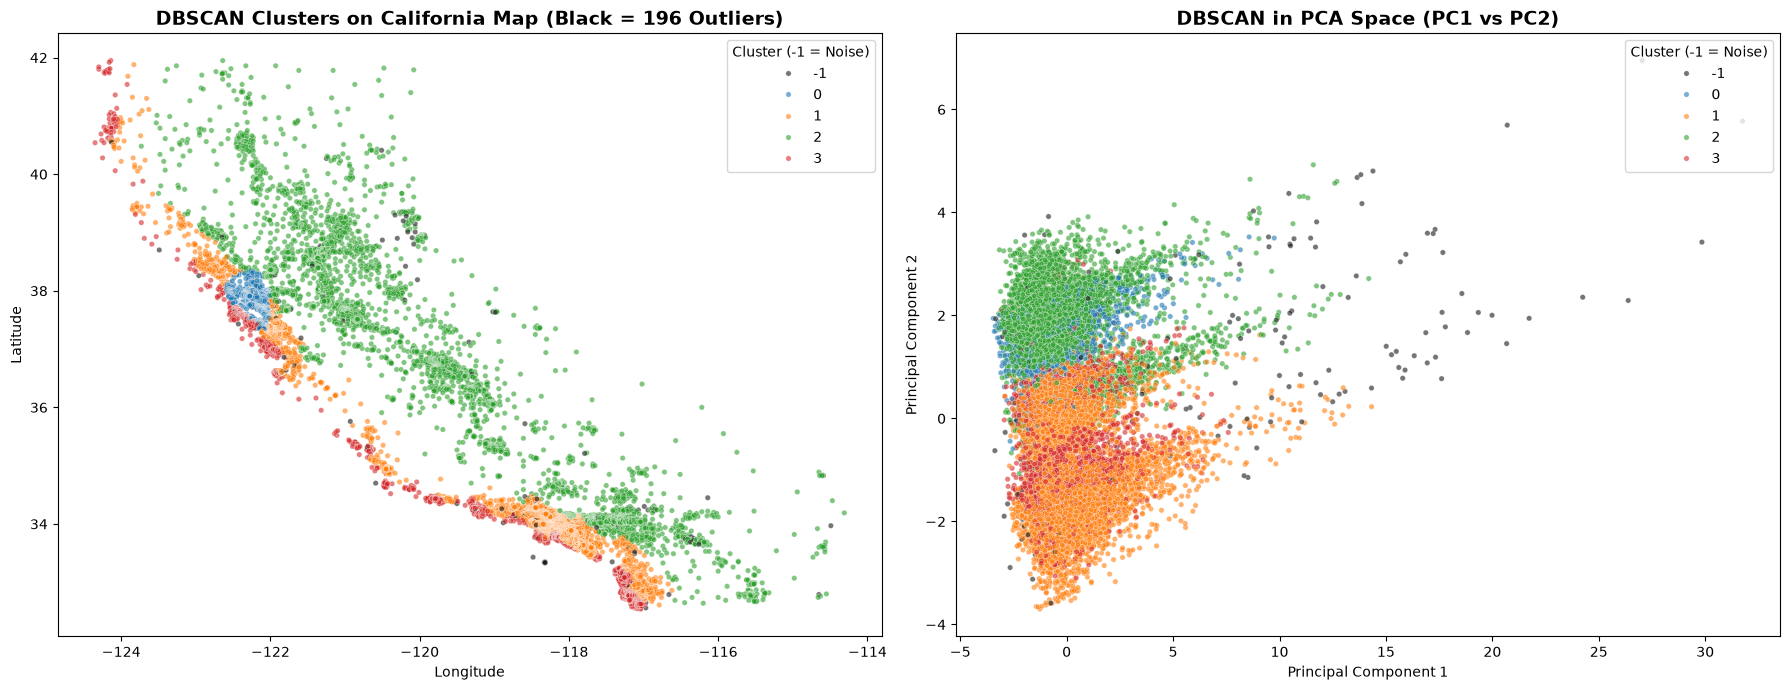

In [52]:
# Plot DBSCAN Clusters and Outliers
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Create a custom palette where noise (-1) is distinct (black/red)
unique_labels = sorted(df['cluster_dbscan'].unique())
palette = {label: sns.color_palette("tab10")[i] for i, label in enumerate(unique_labels if -1 not in unique_labels else unique_labels[1:])}
if -1 in unique_labels:
    palette[-1] = (0.1, 0.1, 0.1)  # Color noise points dark black

# Left Plot: California Geography
sns.scatterplot(
    data=df,
    x='longitude',
    y='latitude',
    hue='cluster_dbscan',
    palette=palette,
    alpha=0.6,
    s=15,
    ax=axes[0]
)
axes[0].set_title(f"DBSCAN Clusters on California Map (Black = {n_noise_} Outliers)", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].legend(title="Cluster (-1 = Noise)", loc="upper right")

# Right Plot: PCA Space
sns.scatterplot(
    data=df_pca,
    x='PC1',
    y='PC2',
    hue='cluster_dbscan',
    palette=palette,
    alpha=0.6,
    s=15,
    ax=axes[1]
)
axes[1].set_title("DBSCAN in PCA Space (PC1 vs PC2)", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].legend(title="Cluster (-1 = Noise)", loc="upper right")

plt.tight_layout()
plt.show()

1. Where the Noise is Staring Right at Us (Right Plot - PCA Space)

Look at the right half of the PCA graph:

- Notice all those lone dark black/grey dots stretching out to the right (where PC1 reaches 5, 10, 15, 20, and all the way to 30)?

- In our earlier K-Means plot, those dots were forced into "Cluster 4".

- Here in DBSCAN, **every single one of those isolated dots was caught and labeled black** `(-1 = Noise)`! DBSCAN refused to pretend they belong to a normal community.

#### **Let's "Interrogate" the Outliers — Why are they Noise?**

What makes these 196 neighborhoods so weird? Are they massive vacation resorts? Extreme rural cabins? Empty desert tracts?

**Let's write a quick cell to compare the average statistics of the 196 Outliers vs. the rest of California:**

In [ ]:
# Inspect the 196 Outlier Neighborhoods vs Normal Neighborhoods
outliers = df[df['cluster_dbscan'] == -1]
normal_data = df[df['cluster_dbscan'] != -1]

comparison = pd.DataFrame({
    'Normal California (Average)': normal_data[['median_house_value', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'population']].mean(),
    'DBSCAN Outliers (Average)': outliers[['median_house_value', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'population']].mean(),
    'Outliers Max Value': outliers[['median_house_value', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'population']].max()
})

# Format nicely
comparison['Normal California (Average)'] = comparison['Normal California (Average)'].round(2)
comparison['DBSCAN Outliers (Average)'] = comparison['DBSCAN Outliers (Average)'].round(2)
comparison['Outliers Max Value'] = comparison['Outliers Max Value'].round(2)

display(comparison)

,Normal California (Average),DBSCAN Outliers (Average),Outliers Max Value
median_house_value,206501.59,243804.17,500001.00
median_income,3.86,4.57,15.00
rooms_per_household,5.36,12.33,141.91
bedrooms_per_room,0.21,0.32,2.82
population_per_household,2.93,17.37,1243.33
population,1395.76,4524.98,35682.00


#### **The Anatomy of the Outliers**

1. **The "141 Rooms per House" Anomaly (rooms_per_household):**

- **Normal California:** A typical home has 5.36 rooms.

- **Outliers Average:** 12.33 rooms.

- **Outliers Max:** 141.91 rooms per household!

- **What are these?** These aren't normal family homes. These are likely hotels, ski resorts (like Lake Tahoe), luxury retreat estates, or boarding facilities where census data recorded massive room counts.

2. **The "1,243 People in One House" Anomaly (population_per_household):**

- **Normal California:** About 2.93 people per household (a mom, dad, and child).

- **Outliers Max:** 1,243 people per household!

- **What are these?** These are group quarters, college dormitories, correctional facilities, or military barracks where hundreds of people share a single census-defined living address.

3. **Mega-Populations (population):**

- **Normal California:** Average neighborhood block has ~1,396 people.

- **Outliers Max:** Reached up to 35,682 people crammed into a single block!

**The Big Machine Learning Lesson: K-Means vs. DBSCAN**

- **What K-Means did:** Because K-Means is mathematically forced to assign every single data point to a cluster, it warped its clusters (especially Cluster 4) just to accommodate these 141-room hotels and 1,243-person dormitories.

- **What DBSCAN did:** DBSCAN spotted that these 196 points don't fit normal human residential neighborhoods and cleanly labeled them -1 (Noise), leaving the true housing clusters pure!

### **8. Model Evaluation**

In [54]:
# Final Model Comparison and Synthesis
comparison_summary = pd.DataFrame({
    'Metric / Feature': [
        'Model Type',
        'Clusters Found',
        'Handling of Outliers',
        'Cluster Shapes Assumed',
        'Best Use Case in Real Estate'
    ],
    'K-Means': [
        'Centroid / Partition-based',
        '5 (manually chosen via Elbow & Silhouette)',
        'Forces outliers into nearest cluster (vulnerable)',
        'Spherical / Round clusters',
        'Broad market segmentation & demographic personas'
    ],
    'DBSCAN': [
        'Density-based spatial clustering',
        f"{n_clusters_} dense clusters + {n_noise_} outliers",
        'Explicitly isolates noise (-1) (very robust)',
        'Arbitrary, natural shapes (follows coastlines/valleys)',
        'Anomaly detection, resort identification & filtering data errors'
    ]
})

display(comparison_summary)

,Metric / Feature,K-Means,DBSCAN
0,Model Type,Centroid / Partition-based,Density-based spatial clustering
1,Clusters Found,5 (manually chosen via Elbow & Silhouette),5 dense clusters + 196 outliers
2,Handling of Outliers,Forces outliers into nearest cluster (vulnerable),Explicitly isolates noise (-1) (very robust)
3,Cluster Shapes Assumed,Spherical / Round clusters,"Arbitrary, natural shapes (follows coastlines/..."
4,Best Use Case in Real Estate,Broad market segmentation & demographic personas,"Anomaly detection, resort identification & fil..."


### **9. Key Findings**

## Executive Summary & Key Findings

### 1. Geographical & Economic Realities
- **The Coastal vs. Inland Divide:** Ocean proximity and longitude are the primary drivers of house prices in California. Homes in the Inland/Central Valley average ~$121,000, while Coastal and Bay Area homes average ~$240,000 to ~$260,000.
- **Historic Wealth Hub:** The San Francisco Bay Area (K-Means Cluster 3) is uniquely characterized by the oldest housing stock (~38 years), the smallest household sizes (2.62 people), and the highest home values.
- **Emerging Growth Suburbs:** Newly developed communities (~15 years old) attract higher-earning families looking for larger homes.

### 2. K-Means vs. DBSCAN in Practice
- **K-Means ($K=5$)** excelled at segmenting the entire state into clear demographic personas and actionable customer market segments.
- **DBSCAN ($\epsilon=2.5, \text{min\_samples}=10$)** identified 5 natural dense clusters and successfully flagged **196 extreme outliers (0.95%)**.
- **Anomaly Detection:** Outlier inspection proved that these 196 neighborhoods contained institutional quarters, resorts, or data anomalies (averaging up to 141 rooms per house and 1,243 people per household), demonstrating why density-based clustering is essential for data hygiene.